# TP3 · Clasificación de etapas de adopción de IA

**Pregunta:** ¿Se puede predecir la etapa de adopción (`none`, `pilot`, `partial`, `full`) usando características de contexto de la empresa y del período?

`ai_adoption_stage` se deriva por intervalos de `ai_adoption_rate`; por eso se excluyen ambas variables derivadas (`ai_adoption_rate` y `years_using_ai`) y se particiona por empresa. Se informa el desbalance de clases, se comparan cuatro clasificadores y se reservan empresas completas para la prueba. El clustering es complementario: se ajusta sin etiquetas en entrenamiento y luego se compara con las clases reales en prueba.

In [1]:
import os
import warnings
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores.*", category=UserWarning, module="joblib.externals.loky.backend.context")

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score, precision_score, recall_score,
    cohen_kappa_score, make_scorer, silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
)
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

DIRECTORIO = Path.cwd().resolve()
PROYECTO = DIRECTORIO if DIRECTORIO.name == "proyecto_equipo" else DIRECTORIO / "proyecto_equipo"
if not (PROYECTO / "notebooks").is_dir():
    raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde proyecto_equipo")
RUTA_PARQUET = PROYECTO / "datos" / "derivados" / "ai_company_adoption_limpio.parquet"
if not RUTA_PARQUET.exists():
    raise FileNotFoundError("Ejecutá primero 02_limpieza_ai.ipynb para generar el Parquet limpio")
SALIDAS = PROYECTO / "salidas"
SALIDAS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(RUTA_PARQUET)
assert df.shape == (150_000, 43), f"Dimensiones inesperadas: {df.shape}"
print(f"Dataset: {len(df):,} filas | {df['company_id'].nunique():,} empresas | datos derivados del proyecto")

Dataset: 150,000 filas | 10,000 empresas | datos derivados del proyecto


## Marco experimental

La regresión logística multinomial es la referencia lineal. El árbol evalúa reglas no lineales interpretables; Gaussian Naive Bayes usa un supuesto probabilístico distinto; Random Forest prueba un ensamble de árboles. Las clases menos frecuentes reciben mayor peso en los modelos que admiten `class_weight`. Se reportan Accuracy junto con precision, recall y F1 macro/ponderado para no ocultar errores de clases minoritarias.

In [2]:
target_col = "ai_adoption_stage"
orden_etapas = ["none", "pilot", "partial", "full"]
y = df[target_col].astype("category").cat.reorder_categories(orden_etapas, ordered=True)

# Objetivo y predictores. La etiqueta se deriva de ai_adoption_rate, por eso se excluye
# tanto la tasa como years_using_ai y las métricas contemporáneas de impacto.
cols_cat = ["country", "industry"]
cols_log = ["num_employees", "annual_revenue_usd_millions"]
cols_std = ["company_age", "survey_year", "num_ai_tools_used", "ai_training_hours"]
predictores = cols_cat + cols_log + cols_std
X = df[predictores].copy()
grupos = df["company_id"].astype("string")

# Partición 80/20 que mantiene juntas las filas por empresa y aproxima estratificación por clase.
partidor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
train_idx, test_idx = next(partidor.split(X, y, groups=grupos))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train, grupos_test = grupos.iloc[train_idx], grupos.iloc[test_idx]
assert set(grupos_train).isdisjoint(set(grupos_test))

frecuencias = []
for nombre, etiquetas in [("Total", y), ("Entrenamiento", y_train), ("Prueba", y_test)]:
    v = etiquetas.value_counts(normalize=True).reindex(orden_etapas).fillna(0)
    frecuencias.append(pd.DataFrame({"Conjunto": nombre, "Clase": orden_etapas, "Porcentaje (%)": (100*v).round(2).values}))
distribucion = pd.concat(frecuencias, ignore_index=True)
display(distribucion.pivot(index="Clase", columns="Conjunto", values="Porcentaje (%)"))
print(f"Entrenamiento: {len(X_train):,} filas / {grupos_train.nunique():,} empresas")
print(f"Prueba: {len(X_test):,} filas / {grupos_test.nunique():,} empresas; empresas compartidas: 0")

Conjunto,Entrenamiento,Prueba,Total
Clase,,,
full,1.12,1.12,1.12
none,3.46,3.47,3.47
partial,52.54,52.51,52.53
pilot,42.87,42.90,42.88


Entrenamiento: 119,996 filas / 8,000 empresas
Prueba: 30,004 filas / 2,000 empresas; empresas compartidas: 0


In [3]:
def crear_preprocesador():
    prep_log = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler()),
    ])
    prep_std = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    prep_cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("log", prep_log, cols_log),
        ("std", prep_std, cols_std),
        ("cat", prep_cat, cols_cat),
    ], remainder="drop")

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression es la referencia lineal y pondera las clases menos frecuentes.
pipe_lr = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", LogisticRegression(max_iter=500, class_weight="balanced", random_state=SEMILLA)),
])
# Árbol acotado y hojas grandes para reducir varianza y evitar hojas con pocos casos.
pipe_dt = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA)),
])
# GaussianNB aporta una referencia probabilística con supuestos distintos.
pipe_nb = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", GaussianNB()),
])
# Random Forest evalúa si un ensamble de árboles mejora los modelos individuales.
pipe_rf = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=20,
        class_weight="balanced", random_state=SEMILLA, n_jobs=2,
    )),
])
modelos_clasif = {
    "Regresión logística": pipe_lr,
    "Árbol de decisión": pipe_dt,
    "Naive Bayes": pipe_nb,
    "Random Forest (ensamble)": pipe_rf,
}
print("Cuatro clasificadores inicializados; la regresión logística se usa como referencia.")

Cuatro clasificadores inicializados; la regresión logística se usa como referencia.


In [5]:
# La consigna recomienda regresión logística como baseline; Dummy prior agrega un piso simple.
pipe_lr = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", LogisticRegression(C=1.0, max_iter=700, class_weight="balanced", random_state=SEMILLA)),
])
pipe_dummy = Pipeline([("prepro", crear_preprocesador()), ("modelo", DummyClassifier(strategy="prior"))])
# Profundidad y tamaño mínimo de hoja limitan reglas frágiles; class_weight atiende el desbalance.
pipe_dt = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA)),
])
pipe_nb = Pipeline([("prepro", crear_preprocesador()), ("modelo", GaussianNB())])
# Random Forest es el ensamble bagging; los límites de profundidad/hoja controlan su complejidad.
pipe_rf = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=20,
        class_weight="balanced", random_state=SEMILLA, n_jobs=1,
    )),
])
modelos_cv = {
    "Regresión logística (baseline C=1)": pipe_lr,
    "Dummy (prior)": pipe_dummy,
    "Árbol de decisión": pipe_dt,
    "Naive Bayes": pipe_nb,
    "Random Forest (ensamble)": pipe_rf,
}
print("La regresión logística es el baseline recomendado; Dummy prior funciona como piso de referencia.")

La regresión logística es el baseline recomendado; Dummy prior funciona como piso de referencia.


In [6]:
# Validación cruzada estratificada y agrupada; las filas de una empresa nunca cruzan folds.
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA + 1)
cv_splits = list(cv_grupos.split(X_train, y_train, groups=grupos_train))
scoring_clasif = {
    "Accuracy": "accuracy",
    "Precision macro": make_scorer(precision_score, average="macro", zero_division=0),
    "Recall macro": make_scorer(recall_score, average="macro", zero_division=0),
    "F1 macro": make_scorer(f1_score, average="macro", zero_division=0),
    "F1 ponderado": make_scorer(f1_score, average="weighted", zero_division=0),
    "Kappa": make_scorer(cohen_kappa_score),
}
resultados_cv_tp3 = {}
for nombre, modelo in modelos_cv.items():
    resultados_cv_tp3[nombre] = cross_validate(
        modelo, X_train, y_train, cv=cv_splits, scoring=scoring_clasif,
        return_train_score=True, n_jobs=1,
    )

# Búsqueda de C para logística usando los mismos folds agrupados; el test no participa.
# Se conserva la logística C=1 como baseline visible y se compara también la versión ajustada.
grilla_logistica = GridSearchCV(
    pipe_lr,
    param_grid={"modelo__C": [0.03, 0.1, 0.3, 1.0, 3.0, 10.0]},
    scoring="f1_macro", cv=cv_splits, n_jobs=1, return_train_score=True, refit=True,
)
grilla_logistica.fit(X_train, y_train)
pipe_lr_ajustada = grilla_logistica.best_estimator_
print(f"GridSearchCV logística: C={grilla_logistica.best_params_['modelo__C']}; F1 macro CV={grilla_logistica.best_score_:.3f}")

filas_cv_tp3 = []
for nombre, r in resultados_cv_tp3.items():
    fila = {"Modelo": nombre}
    for metrica in ["Accuracy", "Precision macro", "Recall macro", "F1 macro", "F1 ponderado", "Kappa"]:
        vals = r[f"test_{metrica}"]
        tr = r[f"train_{metrica}"]
        fila[f"{metrica} CV (media ± DE)"] = f"{vals.mean():.3f} ± {vals.std(ddof=1):.3f}"
        if metrica == "F1 macro":
            fila["F1 macro CV media"] = vals.mean()
            fila["F1 macro train CV media"] = tr.mean()
            fila["Brecha F1 macro CV"] = tr.mean() - vals.mean()
    filas_cv_tp3.append(fila)
# Recuperar scores por fold para C ganador, no solo el máximo agregado.
idx_c = grilla_logistica.best_index_
fold_f1 = np.array([grilla_logistica.cv_results_[f"split{i}_test_score"][idx_c] for i in range(len(cv_splits))])
fold_f1_train = np.array([grilla_logistica.cv_results_[f"split{i}_train_score"][idx_c] for i in range(len(cv_splits))])
filas_cv_tp3.append({
    "Modelo": "Regresión logística (GridSearchCV)",
    "F1 macro CV (media ± DE)": f"{fold_f1.mean():.3f} ± {fold_f1.std(ddof=1):.3f}",
    "F1 macro CV media": fold_f1.mean(), "F1 macro train CV media": fold_f1_train.mean(),
    "Brecha F1 macro CV": fold_f1_train.mean() - fold_f1.mean(),
})
df_cv_tp3 = pd.DataFrame(filas_cv_tp3).sort_values("F1 macro CV media", ascending=False)
display(df_cv_tp3.drop(columns=["F1 macro CV media", "F1 macro train CV media", "Brecha F1 macro CV"], errors="ignore"))
df_cv_tp3.to_csv(SALIDAS / "validacion_cruzada_tp3.csv", index=False)

modelos_clasif = {
    "Regresión logística (baseline)": pipe_lr,
    "Regresión logística (GridSearchCV)": pipe_lr_ajustada,
    "Dummy (prior)": pipe_dummy,
    "Árbol de decisión": pipe_dt,
    "Naive Bayes": pipe_nb,
    "Random Forest (ensamble)": pipe_rf,
}
predicciones_train, predicciones_test = {}, {}
for nombre, modelo in modelos_clasif.items():
    modelo.fit(X_train, y_train)
    predicciones_train[nombre] = modelo.predict(X_train)
    predicciones_test[nombre] = modelo.predict(X_test)
    print(f"Entrenado y evaluado en hold-out: {nombre}")

GridSearchCV logística: C=10.0; F1 macro CV=0.490


,Modelo,Accuracy CV (media ± DE),Precision macro CV (media ± DE),Recall macro CV (media ± DE),F1 macro CV (media ± DE),F1 ponderado CV (media ± DE),Kappa CV (media ± DE)
5,Regresión logística (GridSearchCV),NaN,NaN,NaN,0.490 ± 0.002,NaN,NaN
0,Regresión logística (baseline C=1),0.628 ± 0.001,0.464 ± 0.001,0.755 ± 0.008,0.490 ± 0.003,0.657 ± 0.000,0.394 ± 0.000
4,Random Forest (ensamble),0.612 ± 0.002,0.454 ± 0.002,0.750 ± 0.011,0.475 ± 0.004,0.643 ± 0.002,0.373 ± 0.003
2,Árbol de decisión,0.612 ± 0.007,0.455 ± 0.003,0.739 ± 0.009,0.475 ± 0.006,0.644 ± 0.005,0.374 ± 0.008
3,Naive Bayes,0.533 ± 0.008,0.386 ± 0.005,0.601 ± 0.014,0.396 ± 0.008,0.560 ± 0.007,0.249 ± 0.009
1,Dummy (prior),0.525 ± 0.000,0.131 ± 0.000,0.250 ± 0.000,0.172 ± 0.000,0.362 ± 0.000,0.000 ± 0.000


Entrenado y evaluado en hold-out: Regresión logística (baseline)
Entrenado y evaluado en hold-out: Regresión logística (GridSearchCV)
Entrenado y evaluado en hold-out: Dummy (prior)
Entrenado y evaluado en hold-out: Árbol de decisión
Entrenado y evaluado en hold-out: Naive Bayes
Entrenado y evaluado en hold-out: Random Forest (ensamble)


In [7]:
filas_metricas = []
for nombre in modelos_clasif:
    y_pred_tr, y_pred_te = predicciones_train[nombre], predicciones_test[nombre]
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy (Train)": round(accuracy_score(y_train, y_pred_tr), 3),
        "Accuracy (Test)": round(accuracy_score(y_test, y_pred_te), 3),
        "Precision macro (Train)": round(precision_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "Precision macro (Test)": round(precision_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "Recall macro (Train)": round(recall_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "Recall macro (Test)": round(recall_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "F1 macro (Train)": round(f1_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "F1 macro (Test)": round(f1_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "F1 ponderado (Train)": round(f1_score(y_train, y_pred_tr, average="weighted", zero_division=0), 3),
        "F1 ponderado (Test)": round(f1_score(y_test, y_pred_te, average="weighted", zero_division=0), 3),
        "Kappa (Train)": round(cohen_kappa_score(y_train, y_pred_tr), 3),
        "Kappa (Test)": round(cohen_kappa_score(y_test, y_pred_te), 3),
        "Brecha F1 macro": round(f1_score(y_train, y_pred_tr, average="macro", zero_division=0) - f1_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
    })
df_comparativa_tp3 = pd.DataFrame(filas_metricas)
display(df_comparativa_tp3)
df_comparativa_tp3.to_csv(SALIDAS / "tabla_comparativa_clasificacion_tp3.csv", index=False)

# Elegir familia por F1 macro medio de validación; usar test solo como evaluación final.
cv_por_nombre = df_cv_tp3.set_index("Modelo")
mapa_cv_holdout = {
    "Regresión logística (baseline)": "Regresión logística (baseline C=1)",
    "Regresión logística (GridSearchCV)": "Regresión logística (GridSearchCV)",
}
criterios = []
for nombre in modelos_clasif:
    cv_nombre = mapa_cv_holdout.get(nombre, nombre)
    criterios.append((nombre, cv_por_nombre.loc[cv_nombre, "F1 macro CV media"]))
mejor_clasificador = max(criterios, key=lambda par: par[1])[0]
print(f"Mejor clasificador por F1 macro CV: {mejor_clasificador}; F1 macro CV={dict(criterios)[mejor_clasificador]:.3f}")

,Modelo,Accuracy (Train),Accuracy (Test),Precision macro (Train),Precision macro (Test),Recall macro (Train),Recall macro (Test),F1 macro (Train),F1 macro (Test),F1 ponderado (Train),F1 ponderado (Test),Kappa (Train),Kappa (Test),Brecha F1 macro
0,Regresión logística (baseline),0.628,0.633,0.465,0.467,0.760,0.759,0.491,0.495,0.657,0.660,0.394,0.398,-0.004
1,Regresión logística (GridSearchCV),0.628,0.632,0.465,0.467,0.760,0.759,0.491,0.495,0.657,0.659,0.394,0.398,-0.003
2,Dummy (prior),0.525,0.525,0.131,0.131,0.250,0.250,0.172,0.172,0.362,0.362,0.000,0.000,0.000
3,Árbol de decisión,0.617,0.618,0.465,0.462,0.765,0.742,0.487,0.484,0.647,0.648,0.383,0.382,0.003
4,Naive Bayes,0.541,0.533,0.394,0.382,0.630,0.584,0.408,0.394,0.566,0.557,0.259,0.241,0.015
5,Random Forest (ensamble),0.613,0.611,0.456,0.452,0.771,0.743,0.476,0.470,0.645,0.643,0.378,0.373,0.006


Mejor clasificador por F1 macro CV: Regresión logística (GridSearchCV); F1 macro CV=0.490


In [8]:
for nombre in modelos_clasif:
    print("=" * 65, f"\nREPORTE DE ENTRENAMIENTO: {nombre}", "=" * 65)
    print(classification_report(
        y_train, predicciones_train[nombre], labels=orden_etapas,
        target_names=orden_etapas, zero_division=0,
    ))
    print("=" * 65, f"\nREPORTE DE PRUEBA: {nombre}", "=" * 65)
    print(classification_report(
        y_test, predicciones_test[nombre], labels=orden_etapas,
        target_names=orden_etapas, zero_division=0,
    ))

REPORTE DE ENTRENAMIENTO: Regresión logística (baseline) =================================================================
              precision    recall  f1-score   support

        none       0.28      0.95      0.43      4157
       pilot       0.69      0.60      0.64     51446
     partial       0.78      0.62      0.69     63045
        full       0.11      0.87      0.20      1348

    accuracy                           0.63    119996
   macro avg       0.46      0.76      0.49    119996
weighted avg       0.72      0.63      0.66    119996

REPORTE DE PRUEBA: Regresión logística (baseline) =================================================================
              precision    recall  f1-score   support

        none       0.28      0.93      0.44      1041
       pilot       0.69      0.60      0.64     12871
     partial       0.78      0.63      0.70     15755
        full       0.11      0.87      0.20       337

    accuracy                           0.63     30004


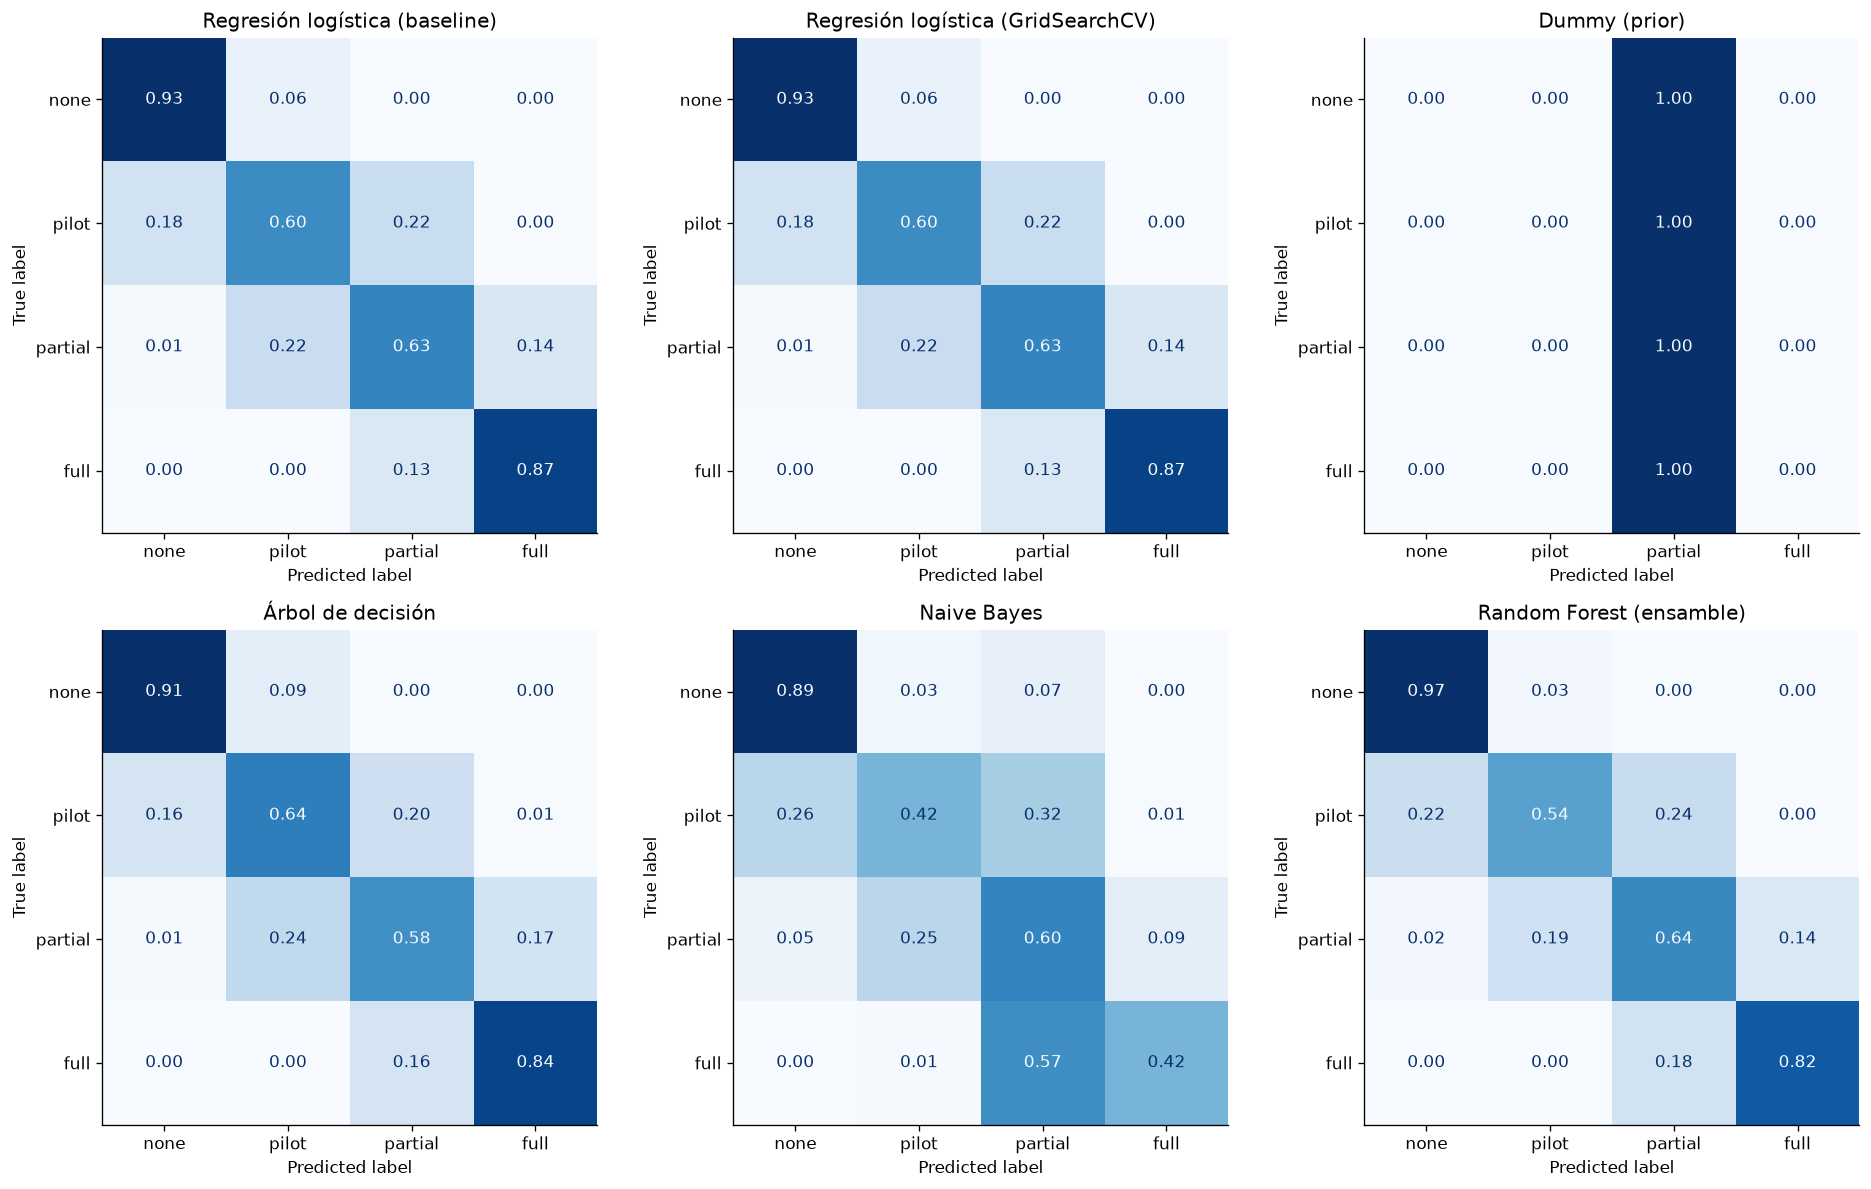

,Predicho no-full,Predicho full
Real no-full,27394,2273
Real full,45,292


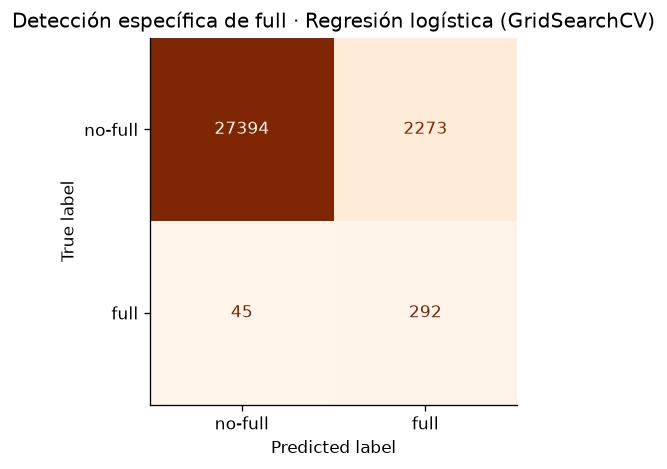

In [9]:
# Matrices de confusión normalizadas por clase para todos los clasificadores.
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (nombre, pred) in zip(axes.flat, predicciones_test.items()):
    cm = confusion_matrix(y_test, pred, labels=orden_etapas, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=orden_etapas).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False
    )
    ax.set_title(nombre)
for ax in axes.flat[len(predicciones_test):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(SALIDAS / "matrices_confusion_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

# Vista binaria específica: detectar la clase rara full frente al resto.
y_full_real = np.asarray(y_test.astype(str) == "full")
y_full_pred = np.asarray(predicciones_test[mejor_clasificador].astype(str) == "full")
cm_full = confusion_matrix(y_full_real, y_full_pred, labels=[False, True])
display(pd.DataFrame(cm_full, index=["Real no-full", "Real full"], columns=["Predicho no-full", "Predicho full"]))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_full, display_labels=["no-full", "full"]).plot(ax=ax, cmap="Oranges", values_format="d", colorbar=False)
ax.set_title(f"Detección específica de full · {mejor_clasificador}")
plt.tight_layout(); plt.savefig(SALIDAS / "confusion_full_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

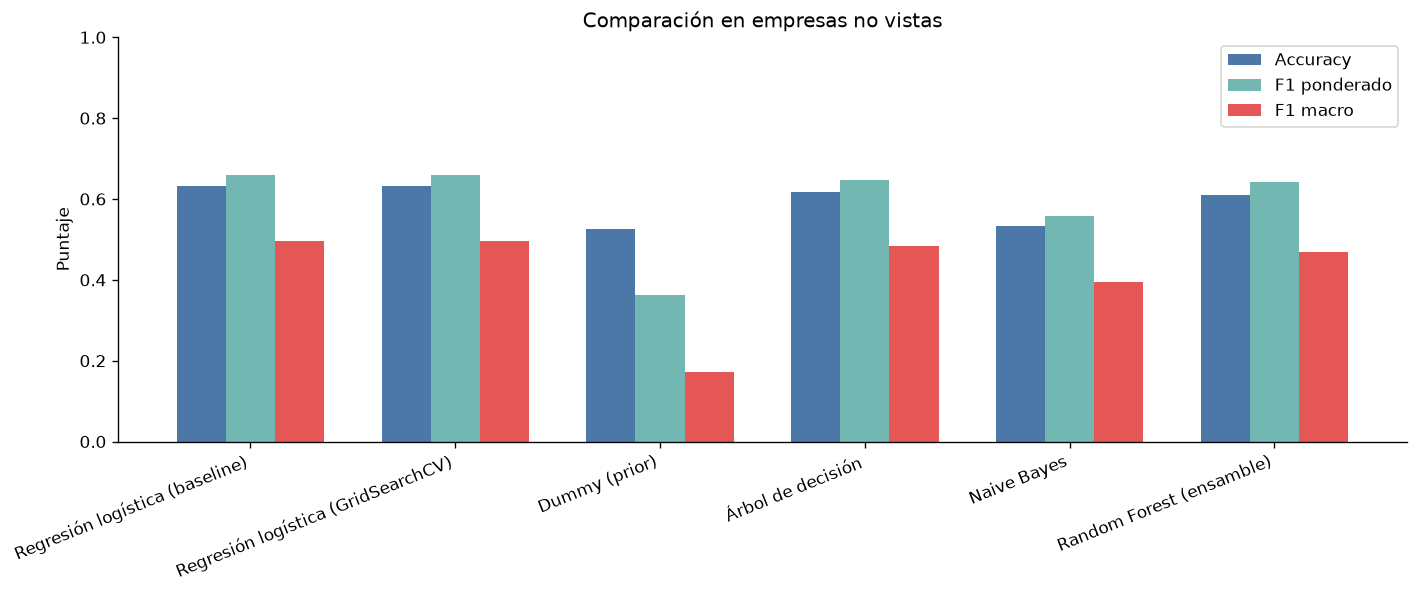

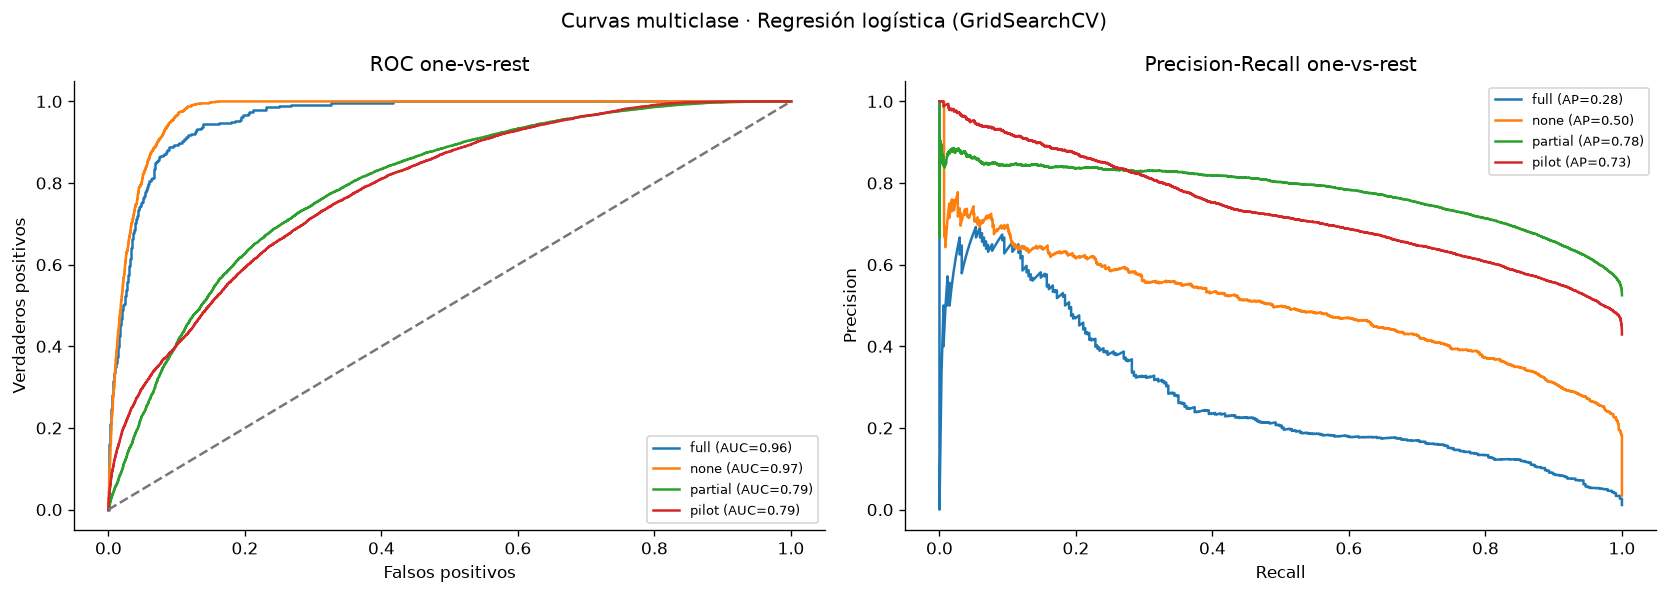

,Variable,Importancia media,Desvío
7,ai_training_hours,0.180099,0.006076
6,num_ai_tools_used,0.093395,0.007912
1,industry,0.008739,0.003874
2,num_employees,0.003746,0.001639
0,country,0.003581,0.005066
3,annual_revenue_usd_millions,0.001761,0.002447
5,survey_year,0.000701,0.001762
4,company_age,-0.000888,0.001017


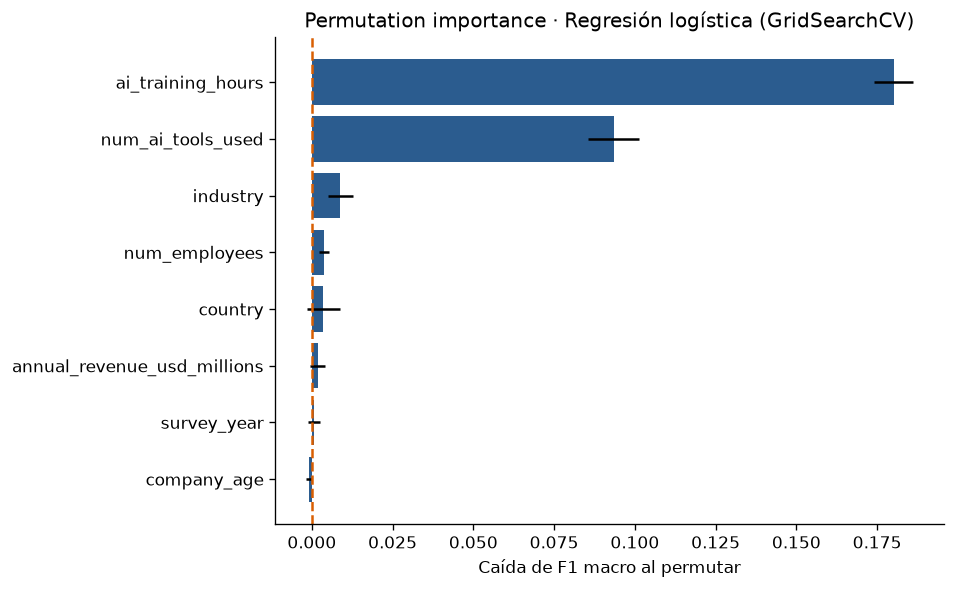

In [10]:
# Métricas comparativas, curvas OVR y permutation importance del mejor modelo por CV.
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_comparativa_tp3)); ancho = 0.24
ax.bar(x-ancho, df_comparativa_tp3["Accuracy (Test)"], ancho, label="Accuracy", color="#4C78A8")
ax.bar(x, df_comparativa_tp3["F1 ponderado (Test)"], ancho, label="F1 ponderado", color="#72B7B2")
ax.bar(x+ancho, df_comparativa_tp3["F1 macro (Test)"], ancho, label="F1 macro", color="#E45756")
ax.set_ylabel("Puntaje"); ax.set_title("Comparación en empresas no vistas")
ax.set_xticks(x, df_comparativa_tp3["Modelo"], rotation=22, ha="right")
ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.savefig(SALIDAS / "comparativa_metricas_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

# Curvas ROC y Precision-Recall one-vs-rest del clasificador seleccionado por CV.
modelo_curvas = modelos_clasif[mejor_clasificador]
proba_test = modelo_curvas.predict_proba(X_test)
clases_modelo = [str(c) for c in modelo_curvas.classes_]
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5))
for i, clase in enumerate(clases_modelo):
    y_bin = (y_test.astype(str).to_numpy() == clase).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, proba_test[:, i])
    ax_roc.plot(fpr, tpr, label=f"{clase} (AUC={auc(fpr,tpr):.2f})")
    prec, rec, _ = precision_recall_curve(y_bin, proba_test[:, i])
    ap = average_precision_score(y_bin, proba_test[:, i])
    ax_pr.plot(rec, prec, label=f"{clase} (AP={ap:.2f})")
ax_roc.plot([0,1], [0,1], "--", color="#777")
ax_roc.set(xlabel="Falsos positivos", ylabel="Verdaderos positivos", title="ROC one-vs-rest")
ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall one-vs-rest")
for ax in (ax_roc, ax_pr): ax.legend(fontsize=8)
fig.suptitle(f"Curvas multiclase · {mejor_clasificador}")
plt.tight_layout(); plt.savefig(SALIDAS / "curvas_roc_pr_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

# Permutation importance sobre variables originales, no sobre columnas one-hot.
rng_perm = np.random.default_rng(SEMILLA)
idx_perm = rng_perm.choice(len(X_test), size=min(3_000, len(X_test)), replace=False)
perm = permutation_importance(
    modelo_curvas, X_test.iloc[idx_perm], y_test.iloc[idx_perm],
    scoring="f1_macro", n_repeats=4, random_state=SEMILLA, n_jobs=1,
)
imp_perm = pd.DataFrame({"Variable": predictores, "Importancia media": perm.importances_mean, "Desvío": perm.importances_std}).sort_values("Importancia media")
display(imp_perm.sort_values("Importancia media", ascending=False))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_perm["Variable"], imp_perm["Importancia media"], xerr=imp_perm["Desvío"], color=COLOR_BASE)
ax.axvline(0, color=COLOR_LINEA, linestyle="--")
ax.set(xlabel="Caída de F1 macro al permutar", title=f"Permutation importance · {mejor_clasificador}")
plt.tight_layout(); plt.savefig(SALIDAS / "permutation_importance_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

,k,Inercia,Silueta,Davies-Bouldin
0,2,94693.5737,0.1699,2.0174
1,3,84785.0367,0.1397,2.1929
2,4,78836.2266,0.1224,2.1378
3,5,74911.9851,0.1178,2.0947
4,6,71724.6224,0.1100,2.0710


Se elige k=2 por la mayor silueta en train; Davies-Bouldin complementa (menor es mejor).


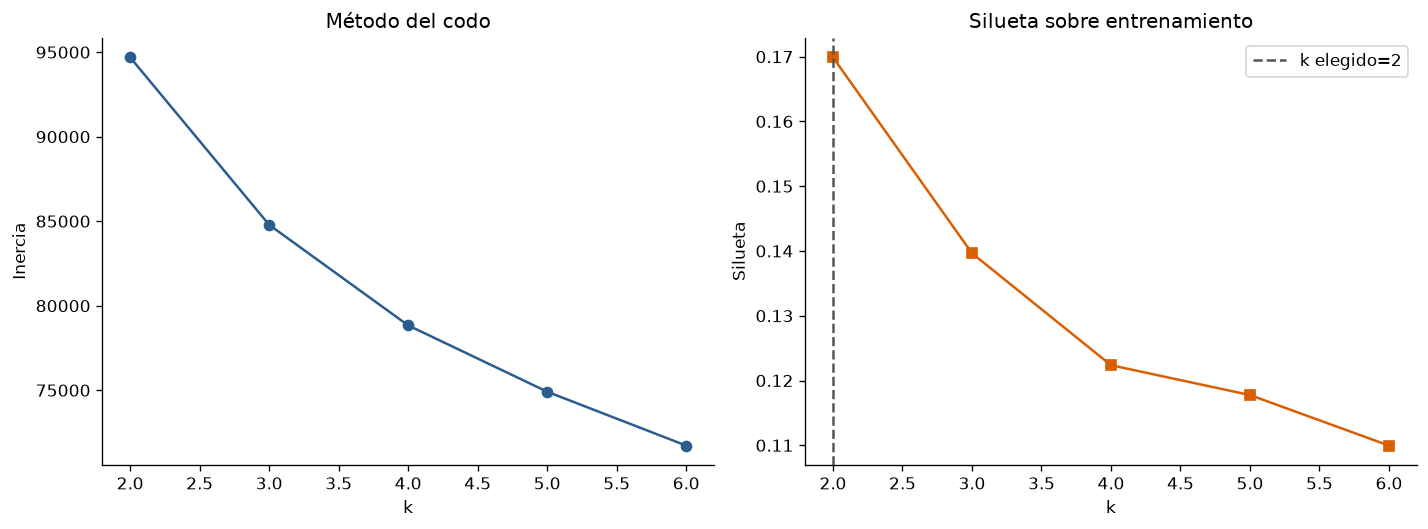

In [11]:
# Seleccionar k con criterios objetivos sobre una muestra de TRAIN, sin consultar las clases.
preprocesador_cluster = crear_preprocesador().fit(X_train)
X_cluster_train = preprocesador_cluster.transform(X_train)
X_cluster_test = preprocesador_cluster.transform(X_test)
rng = np.random.default_rng(SEMILLA)
n_cluster = min(15_000, len(X_cluster_train))
idx_cluster = rng.choice(len(X_cluster_train), size=n_cluster, replace=False)
X_cluster_muestra = X_cluster_train[idx_cluster]
rango_k = range(2, 7)
inercias, siluetas, davies_bouldin = [], [], []
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=5, max_iter=200)
    etiquetas_k = km.fit_predict(X_cluster_muestra)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_cluster_muestra, etiquetas_k, sample_size=min(5_000, len(etiquetas_k)), random_state=SEMILLA))
    davies_bouldin.append(davies_bouldin_score(X_cluster_muestra, etiquetas_k))
k_optimo = list(rango_k)[int(np.argmax(siluetas))]
metricas_k = pd.DataFrame({"k": list(rango_k), "Inercia": inercias, "Silueta": siluetas, "Davies-Bouldin": davies_bouldin})
display(metricas_k.round(4))
print(f"Se elige k={k_optimo} por la mayor silueta en train; Davies-Bouldin complementa (menor es mejor).")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(list(rango_k), inercias, marker="o", color=COLOR_BASE); ax1.set(title="Método del codo", xlabel="k", ylabel="Inercia")
ax2.plot(list(rango_k), siluetas, marker="s", color=COLOR_LINEA); ax2.axvline(k_optimo, linestyle="--", color="#555", label=f"k elegido={k_optimo}")
ax2.set(title="Silueta sobre entrenamiento", xlabel="k", ylabel="Silueta"); ax2.legend()
plt.tight_layout(); plt.savefig(SALIDAS / "seleccion_kmeans_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

,k,ARI vs. clase real,NMI vs. clase real,Silueta train
0,2,0.0526,0.0759,0.1699
1,4,0.0921,0.1115,0.1224


Cluster,Cluster 0,Cluster 1
Etapa real,,
none,3.55,96.45
pilot,19.91,80.09
partial,48.68,51.32
full,70.62,29.38


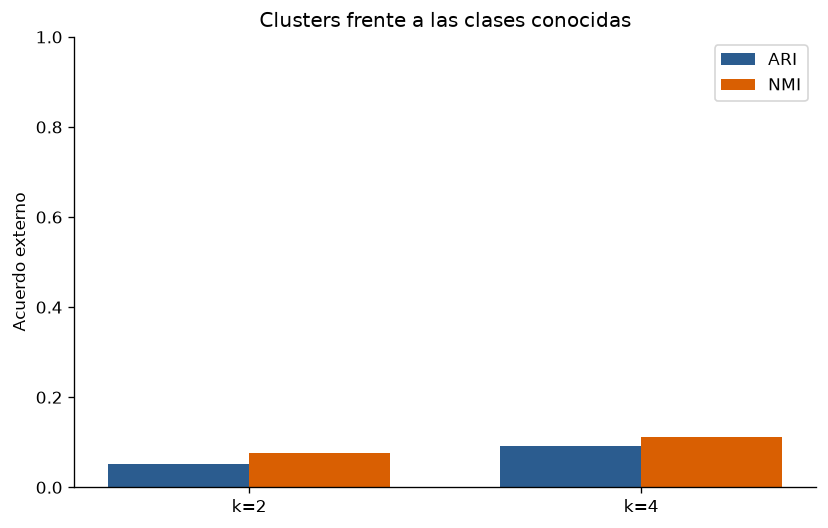

In [12]:
# Comparar explícitamente k=2, k=4 y el óptimo con las clases reales del test.
k_a_comparar = list(dict.fromkeys([2, 4, int(k_optimo)]))
kmeans_por_k, clusters_test_por_k, filas_comparacion_cluster = {}, {}, []
y_test_str = y_test.astype(str).to_numpy()
for k in k_a_comparar:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10, max_iter=300)
    km.fit(X_cluster_muestra)
    labels_k = km.predict(X_cluster_test)
    kmeans_por_k[k], clusters_test_por_k[k] = km, labels_k
    filas_comparacion_cluster.append({
        "k": k,
        "ARI vs. clase real": adjusted_rand_score(y_test_str, labels_k),
        "NMI vs. clase real": normalized_mutual_info_score(y_test_str, labels_k),
        "Silueta train": metricas_k.loc[metricas_k["k"] == k, "Silueta"].iloc[0],
    })
df_comparacion_cluster = pd.DataFrame(filas_comparacion_cluster).sort_values("k")
display(df_comparacion_cluster.round(4))
df_comparacion_cluster.to_csv(SALIDAS / "comparacion_kmeans_clases_tp3.csv", index=False)
clusters_test = clusters_test_por_k[int(k_optimo)]
df_cruce = pd.DataFrame({"Etapa real": y_test_str, "Cluster": [f"Cluster {c}" for c in clusters_test]})
tabla_contingencia = pd.crosstab(df_cruce["Etapa real"], df_cruce["Cluster"], normalize="index").reindex(orden_etapas).fillna(0)*100
display(tabla_contingencia.round(2))
tabla_contingencia.to_csv(SALIDAS / "contingencia_clustering_tp3.csv")
fig, ax = plt.subplots(figsize=(7, 4.5)); xx = np.arange(len(df_comparacion_cluster)); w=.36
ax.bar(xx-w/2, df_comparacion_cluster["ARI vs. clase real"], w, label="ARI", color=COLOR_BASE)
ax.bar(xx+w/2, df_comparacion_cluster["NMI vs. clase real"], w, label="NMI", color=COLOR_LINEA)
ax.set(xticks=xx, xticklabels=[f"k={k}" for k in df_comparacion_cluster["k"]], ylim=(0,1), ylabel="Acuerdo externo", title="Clusters frente a las clases conocidas")
ax.legend(); plt.tight_layout(); plt.savefig(SALIDAS / "ari_nmi_kmeans_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

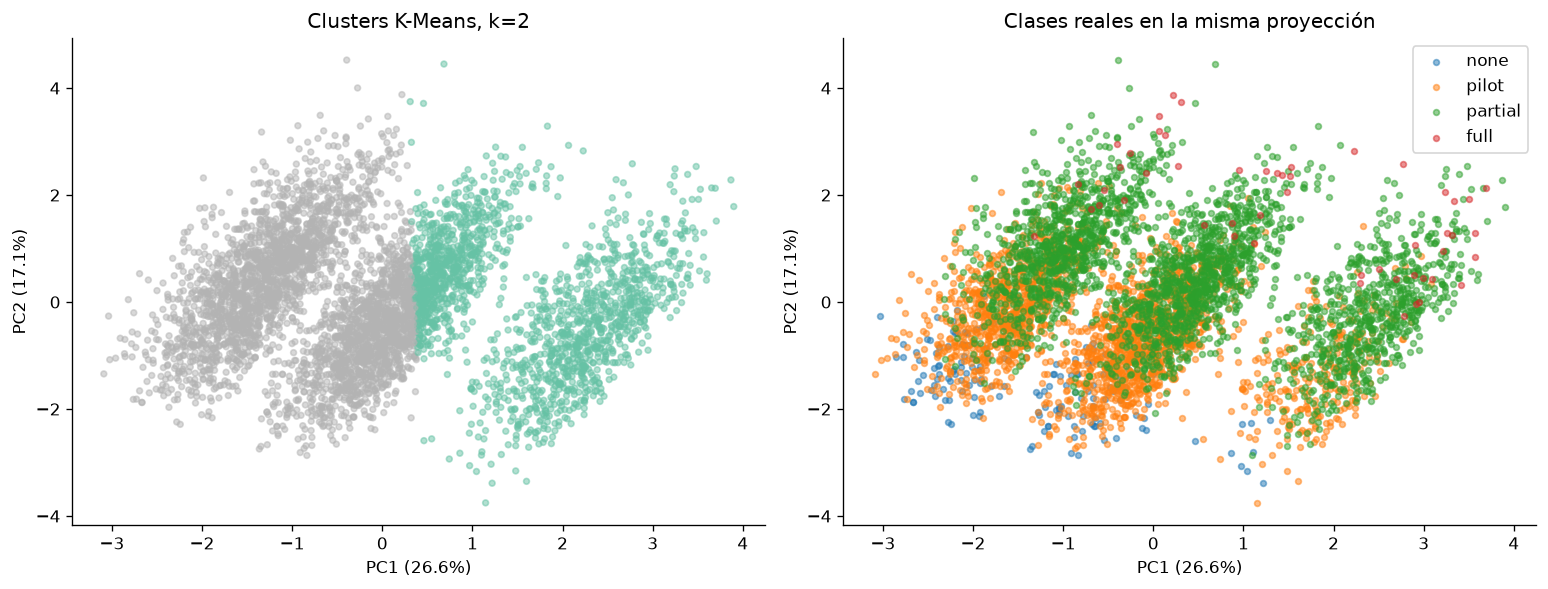

In [13]:
# Visualización PCA del k elegido: un panel coloreado por cluster y otro por clase conocida.
n_pca = min(5_000, len(X_cluster_test))
idx_pca = rng.choice(len(X_cluster_test), size=n_pca, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_cluster_muestra)
X_pca = pca.transform(X_cluster_test[idx_pca])
y_sub_real = y_test.iloc[idx_pca].astype(str).to_numpy()
clusters_sub = clusters_test[idx_pca]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(X_pca[:,0], X_pca[:,1], c=clusters_sub, cmap="Set2", alpha=.5, s=12)
ax1.set_title(f"Clusters K-Means, k={k_optimo}"); ax1.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax1.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
for etapa in orden_etapas:
    mask = y_sub_real == etapa
    ax2.scatter(X_pca[mask,0], X_pca[mask,1], label=etapa, alpha=.5, s=12)
ax2.set_title("Clases reales en la misma proyección"); ax2.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax2.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax2.legend(); plt.tight_layout(); plt.savefig(SALIDAS / "pca_clusters_vs_clases_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

In [14]:
# Persistir el clasificador con mayor F1 macro y casos de prueba de empresas no vistas para Streamlit.
mejores = dict(modelos_clasif)
modelo_clasificacion_seleccionado = mejores[mejor_clasificador]
bundle_clasificacion = {
    "model": modelo_clasificacion_seleccionado,
    "features": predictores,
    "target": target_col,
    "model_name": mejor_clasificador,
    "labels": orden_etapas,
    "category_options": {
        "country": sorted(df["country"].dropna().astype(str).unique().tolist()),
        "industry": sorted(df["industry"].dropna().astype(str).unique().tolist()),
    },
}
joblib.dump(bundle_clasificacion, SALIDAS / "modelo_clasificacion_tp3.joblib")
filas_test = df.iloc[test_idx].copy()
demo_clas = (filas_test.groupby(target_col, observed=True, group_keys=False)
             .head(3).copy().reset_index(drop=True))
demo_clas.insert(0, "demo_id", [f"CLA-{i:02d}" for i in range(1, len(demo_clas)+1)])
demo_clas[["demo_id", "company_id", *predictores, target_col]].to_csv(
    SALIDAS / "muestras_prueba_clasificacion.csv", index=False
)
print(f"Guardado {mejor_clasificador} y {len(demo_clas)} muestras reservadas del test.")

Guardado Regresión logística (GridSearchCV) y 12 muestras reservadas del test.


In [15]:
# Interpretación basada en métricas, matrices, desbalance y actividades complementarias.
from IPython.display import Markdown, display

m = df_comparativa_tp3.set_index("Modelo")
best = m.loc[mejor_clasificador]
rf = m.loc["Random Forest (ensamble)"]
log_base = m.loc["Regresión logística (baseline)"]
delta_rf = rf["F1 macro (Test)"] - log_base["F1 macro (Test)"]
cv_best = dict(criterios)[mejor_clasificador]
clases_pct = (y.value_counts(normalize=True).reindex(orden_etapas)*100).round(2)
score_full = df_cv_tp3[df_cv_tp3["Modelo"] == mapa_cv_holdout.get(mejor_clasificador, mejor_clasificador)]["F1 macro CV media"].iloc[0]
texto = f"""## Interpretación de resultados

1. **Clasificador y baseline.** {mejor_clasificador} quedó primero por F1 macro medio de validación cruzada agrupada ({cv_best:.3f}) y obtuvo Accuracy {best['Accuracy (Test)']:.3f}, F1 macro {best['F1 macro (Test)']:.3f}, F1 ponderado {best['F1 ponderado (Test)']:.3f} y Kappa {best['Kappa (Test)']:.3f} en empresas no vistas. La regresión logística es el baseline recomendado por TP3; Dummy prior ofrece un piso de comparación.
2. **Desbalance y errores.** Las proporciones globales son {', '.join(f'{c} {clases_pct[c]:.2f}%' for c in orden_etapas)}. La clase `full` es minoritaria; accuracy por sí sola puede ocultar que se la detecte mal. Los pesos balanceados de logística, árbol y Random Forest aumentan el costo de ignorar clases raras; reportes y matrices por clase permiten observar el costo en precision y falsos positivos. La matriz binaria de `full` muestra sus falsos negativos y positivos directamente.
3. **Ajuste y ensamble.** La comparación train-test y la brecha F1 macro CV ayudan a detectar sobreajuste. Random Forest difiere del baseline logístico en {delta_rf:+.3f} puntos de F1 macro de test; el cambio debe sopesarse contra mayor costo y menor interpretabilidad, no asumirse como mejora por ser un ensamble.
4. **Clustering.** K-Means se ajusta sin etiquetas, con k elegido por silueta y contrastes explícitos k=2 y k=4. ARI/NMI y la contingencia comparan las agrupaciones con la clase real; una concordancia baja indica que las clases conocidas no forman necesariamente clusters compactos en estas variables. La proyección PCA es exploratoria y no demuestra causalidad.
"""
display(Markdown(texto))

## Interpretación de resultados

1. **Clasificador y baseline.** Regresión logística (GridSearchCV) quedó primero por F1 macro medio de validación cruzada agrupada (0.490) y obtuvo Accuracy 0.632, F1 macro 0.495, F1 ponderado 0.659 y Kappa 0.398 en empresas no vistas. La regresión logística es el baseline recomendado por TP3; Dummy prior ofrece un piso de comparación.
2. **Desbalance y errores.** Las proporciones globales son none 3.47%, pilot 42.88%, partial 52.53%, full 1.12%. La clase `full` es minoritaria; accuracy por sí sola puede ocultar que se la detecte mal. Los pesos balanceados de logística, árbol y Random Forest aumentan el costo de ignorar clases raras; reportes y matrices por clase permiten observar el costo en precision y falsos positivos. La matriz binaria de `full` muestra sus falsos negativos y positivos directamente.
3. **Ajuste y ensamble.** La comparación train-test y la brecha F1 macro CV ayudan a detectar sobreajuste. Random Forest difiere del baseline logístico en -0.025 puntos de F1 macro de test; el cambio debe sopesarse contra mayor costo y menor interpretabilidad, no asumirse como mejora por ser un ensamble.
4. **Clustering.** K-Means se ajusta sin etiquetas, con k elegido por silueta y contrastes explícitos k=2 y k=4. ARI/NMI y la contingencia comparan las agrupaciones con la clase real; una concordancia baja indica que las clases conocidas no forman necesariamente clusters compactos en estas variables. La proyección PCA es exploratoria y no demuestra causalidad.


## Limitaciones

La fuente no documenta cómo se generaron las observaciones. Además, la etapa objetivo se construye por tramos a partir de una tasa continua y las clases tienen tamaños distintos. El rendimiento describe este archivo y la separación de empresas empleada; no demuestra que las mismas tasas de error se mantengan en otra población. La selección final usa F1 macro, pero la elección puede variar si el costo de falsos negativos o falsos positivos cambia en la aplicación.